In [1]:
import torch
import torchvision
import sklearn
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Scikit-learn:", sklearn.__version__)
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Scikit-learn: 1.6.1
GPU: Tesla T4


In [2]:
from torchvision.datasets import OxfordIIITPet

dataset = OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="category",
    download=True
)

print("Dataset downloaded successfully!")
print("Number of images:", len(dataset))
print("Number of classes:", len(dataset.classes))
print("Classes:", dataset.classes)

100%|██████████| 792M/792M [00:05<00:00, 151MB/s]
100%|██████████| 19.2M/19.2M [00:00<00:00, 101MB/s] 


Dataset downloaded successfully!
Number of images: 3680
Number of classes: 37
Classes: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair', 'Chihuahua', 'Egyptian Mau', 'English Cocker Spaniel', 'English Setter', 'German Shorthaired', 'Great Pyrenees', 'Havanese', 'Japanese Chin', 'Keeshond', 'Leonberger', 'Maine Coon', 'Miniature Pinscher', 'Newfoundland', 'Persian', 'Pomeranian', 'Pug', 'Ragdoll', 'Russian Blue', 'Saint Bernard', 'Samoyed', 'Scottish Terrier', 'Shiba Inu', 'Siamese', 'Sphynx', 'Staffordshire Bull Terrier', 'Wheaten Terrier', 'Yorkshire Terrier']


In [3]:
test_dataset = OxfordIIITPet(
    root="./data",
    split="test",
    target_types="category",
    download=True
)

print("Test dataset downloaded successfully!")
print("Number of test images:", len(test_dataset))
print("Number of classes:", len(test_dataset.classes))

print("Same classes:", dataset.classes == test_dataset.classes)

Test dataset downloaded successfully!
Number of test images: 3669
Number of classes: 37
Same classes: True


In [4]:
print("Number of breeds:", len(dataset.classes))

for i, breed in enumerate(dataset.classes):
    print(i, ":", breed)

Number of breeds: 37
0 : Abyssinian
1 : American Bulldog
2 : American Pit Bull Terrier
3 : Basset Hound
4 : Beagle
5 : Bengal
6 : Birman
7 : Bombay
8 : Boxer
9 : British Shorthair
10 : Chihuahua
11 : Egyptian Mau
12 : English Cocker Spaniel
13 : English Setter
14 : German Shorthaired
15 : Great Pyrenees
16 : Havanese
17 : Japanese Chin
18 : Keeshond
19 : Leonberger
20 : Maine Coon
21 : Miniature Pinscher
22 : Newfoundland
23 : Persian
24 : Pomeranian
25 : Pug
26 : Ragdoll
27 : Russian Blue
28 : Saint Bernard
29 : Samoyed
30 : Scottish Terrier
31 : Shiba Inu
32 : Siamese
33 : Sphynx
34 : Staffordshire Bull Terrier
35 : Wheaten Terrier
36 : Yorkshire Terrier


In [5]:
from collections import Counter

trainval_counts = Counter(dataset._labels)
test_counts = Counter(test_dataset._labels)

print("TRAINVAL DISTRIBUTION")
print("-" * 40)

for i, breed in enumerate(dataset.classes):
    print(f"{breed}: {trainval_counts[i]}")

print("\nTEST DISTRIBUTION")
print("-" * 40)

for i, breed in enumerate(test_dataset.classes):
    print(f"{breed}: {test_counts[i]}")

TRAINVAL DISTRIBUTION
----------------------------------------
Abyssinian: 100
American Bulldog: 100
American Pit Bull Terrier: 100
Basset Hound: 100
Beagle: 100
Bengal: 100
Birman: 100
Bombay: 96
Boxer: 100
British Shorthair: 100
Chihuahua: 100
Egyptian Mau: 93
English Cocker Spaniel: 96
English Setter: 100
German Shorthaired: 100
Great Pyrenees: 100
Havanese: 100
Japanese Chin: 100
Keeshond: 100
Leonberger: 100
Maine Coon: 100
Miniature Pinscher: 100
Newfoundland: 96
Persian: 100
Pomeranian: 100
Pug: 100
Ragdoll: 100
Russian Blue: 100
Saint Bernard: 100
Samoyed: 100
Scottish Terrier: 100
Shiba Inu: 100
Siamese: 99
Sphynx: 100
Staffordshire Bull Terrier: 100
Wheaten Terrier: 100
Yorkshire Terrier: 100

TEST DISTRIBUTION
----------------------------------------
Abyssinian: 98
American Bulldog: 100
American Pit Bull Terrier: 100
Basset Hound: 100
Beagle: 100
Bengal: 100
Birman: 100
Bombay: 88
Boxer: 99
British Shorthair: 100
Chihuahua: 100
Egyptian Mau: 97
English Cocker Spaniel: 100
En

In [6]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

# Get the breed label of every image
labels = np.array(dataset._labels)

# Create image indices
indices = np.arange(len(dataset))

# Split into training and validation
train_indices, val_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

# Create the three datasets
train_dataset = Subset(dataset, train_indices)
val_dataset = Subset(dataset, val_indices)

# Official test dataset remains separate
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

Training images: 2944
Validation images: 736
Test images: 3669


In [7]:
train_counts = np.bincount(labels[train_indices], minlength=37)
val_counts = np.bincount(labels[val_indices], minlength=37)
test_counts = np.bincount(np.array(test_dataset._labels), minlength=37)

distribution = pd.DataFrame({
    "Breed": dataset.classes,
    "Training": train_counts,
    "Validation": val_counts,
    "Test": test_counts
})

display(distribution)

print("\nTotal images:")
print(distribution[["Training", "Validation", "Test"]].sum())

,Breed,Training,Validation,Test
0,Abyssinian,80,20,98
1,American Bulldog,80,20,100
2,American Pit Bull Terrier,80,20,100
3,Basset Hound,80,20,100
4,Beagle,80,20,100
5,Bengal,80,20,100
6,Birman,80,20,100
7,Bombay,77,19,88
8,Boxer,80,20,99
9,British Shorthair,80,20,100



Total images:
Training      2944
Validation     736
Test          3669
dtype: int64


In [8]:
from torchvision import transforms
from torchvision.models import (
    mobilenet_v3_small,
    MobileNet_V3_Small_Weights
)

# Load the official pretrained weights
weights = MobileNet_V3_Small_Weights.DEFAULT

# Preprocessing for validation and test
eval_transform = weights.transforms()

# Augmentation for training
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=weights.transforms().mean,
        std=weights.transforms().std
    )
])

print("Training augmentation:", train_transform)
print("Evaluation preprocessing:", eval_transform)

Training augmentation: Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.08, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
Evaluation preprocessing: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [9]:
from torchvision.datasets import OxfordIIITPet
from torch.utils.data import Subset

# Training dataset with augmentation
train_data = OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="category",
    transform=train_transform,
    download=False
)

# Validation dataset without augmentation
val_data = OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="category",
    transform=eval_transform,
    download=False
)

# Official test dataset without augmentation
test_data = OxfordIIITPet(
    root="./data",
    split="test",
    target_types="category",
    transform=eval_transform,
    download=False
)

# Apply our previously created indices
train_dataset = Subset(train_data, train_indices)
val_dataset = Subset(val_data, val_indices)
test_dataset = test_data

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Training: 2944
Validation: 736
Test: 3669


In [10]:
from torch.utils.data import DataLoader

In [11]:
BATCH_SIZE = 16

In [12]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

In [13]:

from torch.utils.data import DataLoader

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Training batches: 184
Validation batches: 46
Test batches: 230


In [14]:

# Import PyTorch for building and training neural networks
import torch
import torch.nn as nn

# Import MobileNetV3 Small and its pretrained ImageNet weights
from torchvision.models import (
    mobilenet_v3_small,
    MobileNet_V3_Small_Weights
)


In [15]:

# Load MobileNetV3 Small with the default pretrained ImageNet weights
weights = MobileNet_V3_Small_Weights.DEFAULT

# Create the pretrained MobileNetV3 Small model
model = mobilenet_v3_small(weights=weights)

# Print the model architecture
print(model)


Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 113MB/s]

MobileNetV3(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): SqueezeExcitation(
          (avgpool): AdaptiveAvgPool2d(output_size=1)
          (fc1): Conv2d(16, 8, kernel_size=(1, 1), stride=(1, 1))
          (fc2): Conv2d(8, 16, kernel_size=(1, 1), stride=(1, 1))
          (activation): ReLU()
          (scale_activation): Hardsigmoid()
        )
        (2): Conv2dNormActivation(
          (0): Conv2d(16, 16

In [16]:

# Display only the classifier part of MobileNetV3
print(model.classifier)


Sequential(
  (0): Linear(in_features=576, out_features=1024, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1024, out_features=1000, bias=True)
)


In [17]:

# Define the number of pet breed classes
num_classes = 37

# Get the number of input features from the original final layer
in_features = model.classifier[3].in_features
#علاش ما كتبناش 1024 مباشرة؟ باش نخليوا الكود مرن ويستعمل العدد الصحيح مباشرة من الـ Model.

# Replace the final classification layer with a new layer for 37 classes
model.classifier[3] = nn.Linear(
    in_features=in_features,
    out_features=num_classes
)

# Display the updated classifier
print(model.classifier)


Sequential(
  (0): Linear(in_features=576, out_features=1024, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1024, out_features=37, bias=True)
)


In [18]:

# Check whether a CUDA-compatible GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Display the selected device
print("Using device:", device)


Using device: cuda


In [19]:

# Move the model parameters to the selected device
model = model.to(device)

# Print the device used by the model
print("Model is running on:", next(model.parameters()).device)


Model is running on: cuda:0


In [20]:

# Set the model to evaluation mode for this test
model.eval()

# Get one batch of images and labels from the training DataLoader
images, labels = next(iter(train_loader))

# Move the images to the same device as the model (GPU)
images = images.to(device)

# Disable gradient calculations because we are only testing the model
with torch.no_grad():

    # Perform a forward pass through the model
    outputs = model(images)

# Display the output shape
print("Output shape:", outputs.shape)

# Display the shape of the input images
print("Input shape:", images.shape)


Output shape: torch.Size([16, 37])
Input shape: torch.Size([16, 3, 224, 224])


In [21]:

# Enable training for all model parameters
for param in model.parameters():
    param.requires_grad = True

# Count the total number of model parameters
total_params = sum(p.numel() for p in model.parameters())

# Count the number of trainable parameters
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

# Display the parameter counts
print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)


Total parameters: 1555781
Trainable parameters: 1555781


In [22]:

# Define the loss function for multi-class classification
criterion = nn.CrossEntropyLoss()

# Define the Adam optimizer using all trainable model parameters
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

# Set the number of training epochs
num_epochs = 10

# Display the training configuration
print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Number of epochs:", num_epochs)


Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)
Learning rate: 0.0001
Number of epochs: 10


In [23]:

# Import time to measure the training duration
import time

def train_one_epoch(model, loader, criterion, optimizer, device):

    # Set the model to training mode
    model.train()

    # Initialize variables to track loss and correct predictions
    running_loss = 0.0
    correct = 0
    total = 0

    # Iterate over all training batches
    for images, labels in loader:

        # Move images and labels to the selected device
        images = images.to(device)
        labels = labels.to(device)

        # Clear gradients from the previous batch
        optimizer.zero_grad()

        # Forward pass: generate predictions
        outputs = model(images)

        # Calculate the classification loss
        loss = criterion(outputs, labels)

        # Backward pass: calculate gradients
        loss.backward()

        # Update model parameters using the optimizer
        optimizer.step()

        # Accumulate the loss for this batch
        running_loss += loss.item() * images.size(0)

        # Get the predicted class with the highest score
        _, predicted = torch.max(outputs, 1)

        # Count correct predictions
        correct += (predicted == labels).sum().item()

        # Count the total number of images
        total += labels.size(0)

    # Calculate average loss and accuracy for the epoch
    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


In [24]:

def evaluate_model(model, loader, criterion, device):

    # Set the model to evaluation mode
    model.eval()

    # Initialize variables to track loss and accuracy
    running_loss = 0.0
    correct = 0
    total = 0

    # Disable gradient calculations during evaluation
    with torch.no_grad():

        # Iterate over all validation batches
        for images, labels in loader:

            # Move images and labels to the selected device
            images = images.to(device)
            labels = labels.to(device)

            # Generate predictions
            outputs = model(images)

            # Calculate the loss
            loss = criterion(outputs, labels)

            # Accumulate the loss
            running_loss += loss.item() * images.size(0)

            # Get the predicted class
            _, predicted = torch.max(outputs, 1)

            # Count correct predictions
            correct += (predicted == labels).sum().item()

            # Count total images
            total += labels.size(0)

    # Calculate average validation loss and accuracy
    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


In [25]:

# Initialize variables to store training history
history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

# Initialize variables to track the best validation accuracy
best_val_accuracy = 0.0

# Measure the total training time
start_time = time.time()

# Train the model for the selected number of epochs
for epoch in range(num_epochs):

    # Train for one complete epoch
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    # Evaluate the model on the validation dataset
    val_loss, val_accuracy = evaluate_model(
        model, val_loader, criterion, device
    )

    # Save the results for this epoch
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    # Save the model with the best validation accuracy
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        torch.save(model.state_dict(), "best_full_finetuning.pth")

    # Display the results for the current epoch
    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

# Calculate the total training time
training_time = time.time() - start_time

# Display the final training results
print("\nBest validation accuracy:", best_val_accuracy)
print("Training time:", round(training_time / 60, 2), "minutes")


Epoch [1/10] Train Loss: 2.9397 | Train Acc: 0.2724 | Val Loss: 1.5387 | Val Acc: 0.6372
Epoch [2/10] Train Loss: 1.5785 | Train Acc: 0.5815 | Val Loss: 0.7641 | Val Acc: 0.7894
Epoch [3/10] Train Loss: 1.0756 | Train Acc: 0.6906 | Val Loss: 0.5959 | Val Acc: 0.8288
Epoch [4/10] Train Loss: 0.9314 | Train Acc: 0.7164 | Val Loss: 0.5262 | Val Acc: 0.8370
Epoch [5/10] Train Loss: 0.8435 | Train Acc: 0.7418 | Val Loss: 0.4701 | Val Acc: 0.8533
Epoch [6/10] Train Loss: 0.7571 | Train Acc: 0.7694 | Val Loss: 0.4293 | Val Acc: 0.8614
Epoch [7/10] Train Loss: 0.7097 | Train Acc: 0.7884 | Val Loss: 0.4230 | Val Acc: 0.8628
Epoch [8/10] Train Loss: 0.6376 | Train Acc: 0.8094 | Val Loss: 0.4523 | Val Acc: 0.8438
Epoch [9/10] Train Loss: 0.5826 | Train Acc: 0.8190 | Val Loss: 0.3791 | Val Acc: 0.8818
Epoch [10/10] Train Loss: 0.5898 | Train Acc: 0.8200 | Val Loss: 0.4091 | Val Acc: 0.8804

Best validation accuracy: 0.8817934782608695
Training time: 3.7 minutes


In [26]:

# Load the model weights from the best validation checkpoint
model.load_state_dict(
    torch.load("best_full_finetuning.pth", map_location=device)
)

# Set the model to evaluation mode
model.eval()

# Confirm that the best checkpoint has been loaded
print("Best Full Fine-Tuning model loaded successfully!")
print("Best validation accuracy:", best_val_accuracy)


Best Full Fine-Tuning model loaded successfully!
Best validation accuracy: 0.8817934782608695


In [27]:

# Load a fresh MobileNetV3 Small model with pretrained ImageNet weights
model_head = mobilenet_v3_small(weights=weights)

# Replace the final classification layer with 37 output classes
model_head.classifier[3] = nn.Linear(
    in_features=model_head.classifier[3].in_features,
    out_features=num_classes
)

# Freeze all feature extractor parameters
for param in model_head.features.parameters():
    param.requires_grad = False

# Keep all classifier parameters trainable
for param in model_head.classifier.parameters():
    param.requires_grad = True

# Move the model to the selected device
model_head = model_head.to(device)

# Display the model's trainable and total parameters
total_params_head = sum(p.numel() for p in model_head.parameters())

trainable_params_head = sum(
    p.numel() for p in model_head.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params_head)
print("Trainable parameters:", trainable_params_head)


Total parameters: 1555781
Trainable parameters: 628773


In [28]:

# Define the cross-entropy loss for 37-class classification
criterion_head = nn.CrossEntropyLoss()

# Create an Adam optimizer using only trainable parameters
optimizer_head = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model_head.parameters()),
    lr=0.001
)

# Set the number of training epochs
num_epochs_head = 10

# Display the classifier-head training configuration
print("Loss function:", criterion_head)
print("Optimizer:", optimizer_head)
print("Learning rate:", optimizer_head.param_groups[0]["lr"])
print("Number of epochs:", num_epochs_head)


Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Learning rate: 0.001
Number of epochs: 10


In [29]:
def train_one_epoch_head(model, loader, criterion, optimizer, device):
    model.train()

    # Keep the frozen feature extractor in evaluation mode
    model.features.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [30]:
#باش ندرّبوا الـ Classifier لمدة 10epochs
import time

# Initialize training history
history_head = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

# Initialize the best validation accuracy
best_val_accuracy_head = 0.0

# Start measuring training time
start_time_head = time.time()

for epoch in range(num_epochs_head):

    # Train the classifier head
    train_loss, train_accuracy = train_one_epoch_head(
        model_head, train_loader, criterion_head, optimizer_head, device
    )

    # Evaluate on the validation set
    val_loss, val_accuracy = evaluate_model(
        model_head, val_loader, criterion_head, device
    )

    # Save metrics
    history_head["train_loss"].append(train_loss)
    history_head["train_accuracy"].append(train_accuracy)
    history_head["val_loss"].append(val_loss)
    history_head["val_accuracy"].append(val_accuracy)

    # Save the best model based on validation accuracy
    if val_accuracy > best_val_accuracy_head:
        best_val_accuracy_head = val_accuracy
        torch.save(model_head.state_dict(), "best_classifier_head.pth")
        best_epoch_head = epoch + 1

    print(
        f"Epoch [{epoch+1}/{num_epochs_head}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy*100:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_accuracy*100:.2f}%"
    )

# Calculate total training time
training_time_head = time.time() - start_time_head

print("\nClassifier-Head Training Completed!")
print(f"Best Validation Accuracy: {best_val_accuracy_head*100:.2f}%")
print(f"Best Epoch: {best_epoch_head}")
print(f"Training Time: {training_time_head/60:.2f} minutes")

Epoch [1/10] Train Loss: 1.3244 Train Acc: 61.38% Val Loss: 0.5056 Val Acc: 83.70%
Epoch [2/10] Train Loss: 0.6928 Train Acc: 78.23% Val Loss: 0.5567 Val Acc: 82.07%
Epoch [3/10] Train Loss: 0.5883 Train Acc: 81.42% Val Loss: 0.4831 Val Acc: 83.83%
Epoch [4/10] Train Loss: 0.5841 Train Acc: 81.39% Val Loss: 0.4586 Val Acc: 85.05%
Epoch [5/10] Train Loss: 0.4859 Train Acc: 84.14% Val Loss: 0.4277 Val Acc: 86.28%
Epoch [6/10] Train Loss: 0.4413 Train Acc: 85.50% Val Loss: 0.4648 Val Acc: 84.78%
Epoch [7/10] Train Loss: 0.4445 Train Acc: 85.90% Val Loss: 0.4902 Val Acc: 84.51%
Epoch [8/10] Train Loss: 0.4161 Train Acc: 86.96% Val Loss: 0.4436 Val Acc: 86.82%
Epoch [9/10] Train Loss: 0.4074 Train Acc: 86.85% Val Loss: 0.3957 Val Acc: 86.41%
Epoch [10/10] Train Loss: 0.4067 Train Acc: 87.36% Val Loss: 0.4727 Val Acc: 85.05%

Classifier-Head Training Completed!
Best Validation Accuracy: 86.82%
Best Epoch: 8
Training Time: 3.28 minutes


In [31]:
#Approach 3. : Step 1 – Prepare the Feature Extractor
# Load a fresh pretrained MobileNetV3 model
feature_extractor = mobilenet_v3_small(weights=weights)

# Freeze all model parameters
for param in feature_extractor.parameters():
    param.requires_grad = False

# Set the model to evaluation mode
feature_extractor.eval()

# Move the model to the selected device
feature_extractor = feature_extractor.to(device)

# Count total and trainable parameters
total_params = sum(p.numel() for p in feature_extractor.parameters())

trainable_params = sum(
    p.numel() for p in feature_extractor.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Feature extractor is ready!")

Total parameters: 2542856
Trainable parameters: 0
Feature extractor is ready!


In [32]:
#Step 2 – Prepare the datasets for feature extraction
# Create a training dataset with evaluation transforms
train_data_eval = OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="category",
    transform=eval_transform,
    download=False
)

# Select the same training indices used in the previous approaches
train_dataset_eval = Subset(train_data_eval, train_indices)

# Create a DataLoader for feature extraction
train_feature_loader = DataLoader(
    train_dataset_eval,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Training samples:", len(train_dataset_eval))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))


Training samples: 2944
Validation samples: 736
Test samples: 3669


In [33]:
#Step 3 – Extract features from images
# Define a function to extract features from a DataLoader
def extract_features(model, loader, device):

    model.eval()

    all_features = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            # Extract feature maps
            x = model.features(images)

            # Apply average pooling
            x = model.avgpool(x)

            # Flatten feature maps into feature vectors
            x = torch.flatten(x, 1)

            # Store features and labels
            all_features.append(x.cpu().numpy())
            all_labels.append(labels.numpy())

    # Combine all batches
    all_features = np.concatenate(all_features, axis=0)
    all_labels = np.concatenate(all_labels, axis=0)

    return all_features, all_labels

In [34]:
#Step 4 – Extract features from the three datasets
import time

# Start measuring feature extraction time
start_extraction_time = time.time()

# Extract training features
X_train_features, y_train_features = extract_features(
    feature_extractor, train_feature_loader, device
)

# Extract validation features
X_val_features, y_val_features = extract_features(
    feature_extractor, val_loader, device
)

# Extract test features
X_test_features, y_test_features = extract_features(
    feature_extractor, test_loader, device
)

# Calculate total extraction time
extraction_time = time.time() - start_extraction_time

# Display feature shapes
print("Training features:", X_train_features.shape)
print("Validation features:", X_val_features.shape)
print("Test features:", X_test_features.shape)
print(f"Feature extraction time: {extraction_time/60:.2f} minutes")

Training features: (2944, 576)
Validation features: (736, 576)
Test features: (3669, 576)
Feature extraction time: 0.73 minutes


In [35]:
#Step 5 – StandardScaler
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit the scaler using training features only
X_train_scaled = scaler.fit_transform(X_train_features)

# Transform validation and test features using the same scaler
X_val_scaled = scaler.transform(X_val_features)
X_test_scaled = scaler.transform(X_test_features)

# Display the resulting shapes
print("Scaled training features:", X_train_scaled.shape)
print("Scaled validation features:", X_val_scaled.shape)
print("Scaled test features:", X_test_scaled.shape)

Scaled training features: (2944, 576)
Scaled validation features: (736, 576)
Scaled test features: (3669, 576)


In [36]:
#Step 6 – Train and select the best SVM
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score
import time

# Define candidate values for C
C_values = [0.01, 0.1, 1, 10]

best_svm = None
best_C = None
best_val_accuracy_svm = 0.0

svm_results = []

# Measure SVM training and validation time
start_svm_time = time.time()

for C in C_values:

    # Create the Linear SVM classifier
    svm = LinearSVC(
        C=C,
        max_iter=10000,
        random_state=42
    )

    # Train SVM using training features only
    svm.fit(X_train_scaled, y_train_features)

    # Predict validation labels
    val_predictions = svm.predict(X_val_scaled)

    # Calculate validation accuracy
    val_accuracy = accuracy_score(
        y_val_features, val_predictions
    )

    svm_results.append({
        "C": C,
        "val_accuracy": val_accuracy
    })

    print(f"C = {C}: Validation Accuracy = {val_accuracy*100:.2f}%")

    # Keep the best model based on validation accuracy
    if val_accuracy > best_val_accuracy_svm:
        best_val_accuracy_svm = val_accuracy
        best_C = C
        best_svm = svm

svm_training_time = time.time() - start_svm_time

print("\nBest SVM Configuration")
print("Best C:", best_C)
print(f"Best Validation Accuracy: {best_val_accuracy_svm*100:.2f}%")
print(f"SVM training and selection time: {svm_training_time:.2f} seconds")

C = 0.01: Validation Accuracy = 87.50%
C = 0.1: Validation Accuracy = 82.88%
C = 1: Validation Accuracy = 81.39%
C = 10: Validation Accuracy = 81.11%

Best SVM Configuration
Best C: 0.01
Best Validation Accuracy: 87.50%
SVM training and selection time: 2218.60 seconds


In [37]:
# Load the best full fine-tuning model Step 7 – Load the best checkpoints
model.load_state_dict(
    torch.load("best_full_finetuning.pth", map_location=device)
)
model.eval()

# Load the best classifier-head model
model_head.load_state_dict(
    torch.load("best_classifier_head.pth", map_location=device)
)
model_head.eval()

# Keep the feature extractor in evaluation mode
feature_extractor.eval()

print("Best Full Fine-Tuning model loaded.")
print("Best Classifier-Head model loaded.")
print("Feature Extractor ready.")
print("Best SVM model:", best_C)

Best Full Fine-Tuning model loaded.
Best Classifier-Head model loaded.
Feature Extractor ready.
Best SVM model: 0.01


In [38]:
#Step 8 – Predict on the Test Set
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# Define a function to get predictions from a neural network
def get_predictions(model, loader, device):

    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            outputs = model(images)
            _, predictions = torch.max(outputs, 1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.numpy())

    return np.array(all_labels), np.array(all_predictions)


# Get predictions from Full Fine-Tuning
y_test, y_pred_full = get_predictions(
    model, test_loader, device
)

# Get predictions from Classifier-Head
_, y_pred_head = get_predictions(
    model_head, test_loader, device
)

# Get predictions from SVM
y_pred_svm = best_svm.predict(X_test_scaled)


# Calculate final test metrics
results = {
    "Full Fine-Tuning": {
        "accuracy": accuracy_score(y_test, y_pred_full),
        "macro_f1": f1_score(y_test, y_pred_full, average="macro")
    },

    "Classifier-Head": {
        "accuracy": accuracy_score(y_test, y_pred_head),
        "macro_f1": f1_score(y_test, y_pred_head, average="macro")
    },

    "Feature Extraction + SVM": {
        "accuracy": accuracy_score(y_test_features, y_pred_svm),
        "macro_f1": f1_score(y_test_features, y_pred_svm, average="macro")
    }
}

# Display the final test results
for name, metrics in results.items():

    print(f"\n{name}")
    print(f"Test Accuracy: {metrics['accuracy']*100:.2f}%")
    print(f"Macro F1-score: {metrics['macro_f1']:.4f}")


Full Fine-Tuning
Test Accuracy: 84.71%
Macro F1-score: 0.8419

Classifier-Head
Test Accuracy: 82.53%
Macro F1-score: 0.8240

Feature Extraction + SVM
Test Accuracy: 83.35%
Macro F1-score: 0.8309


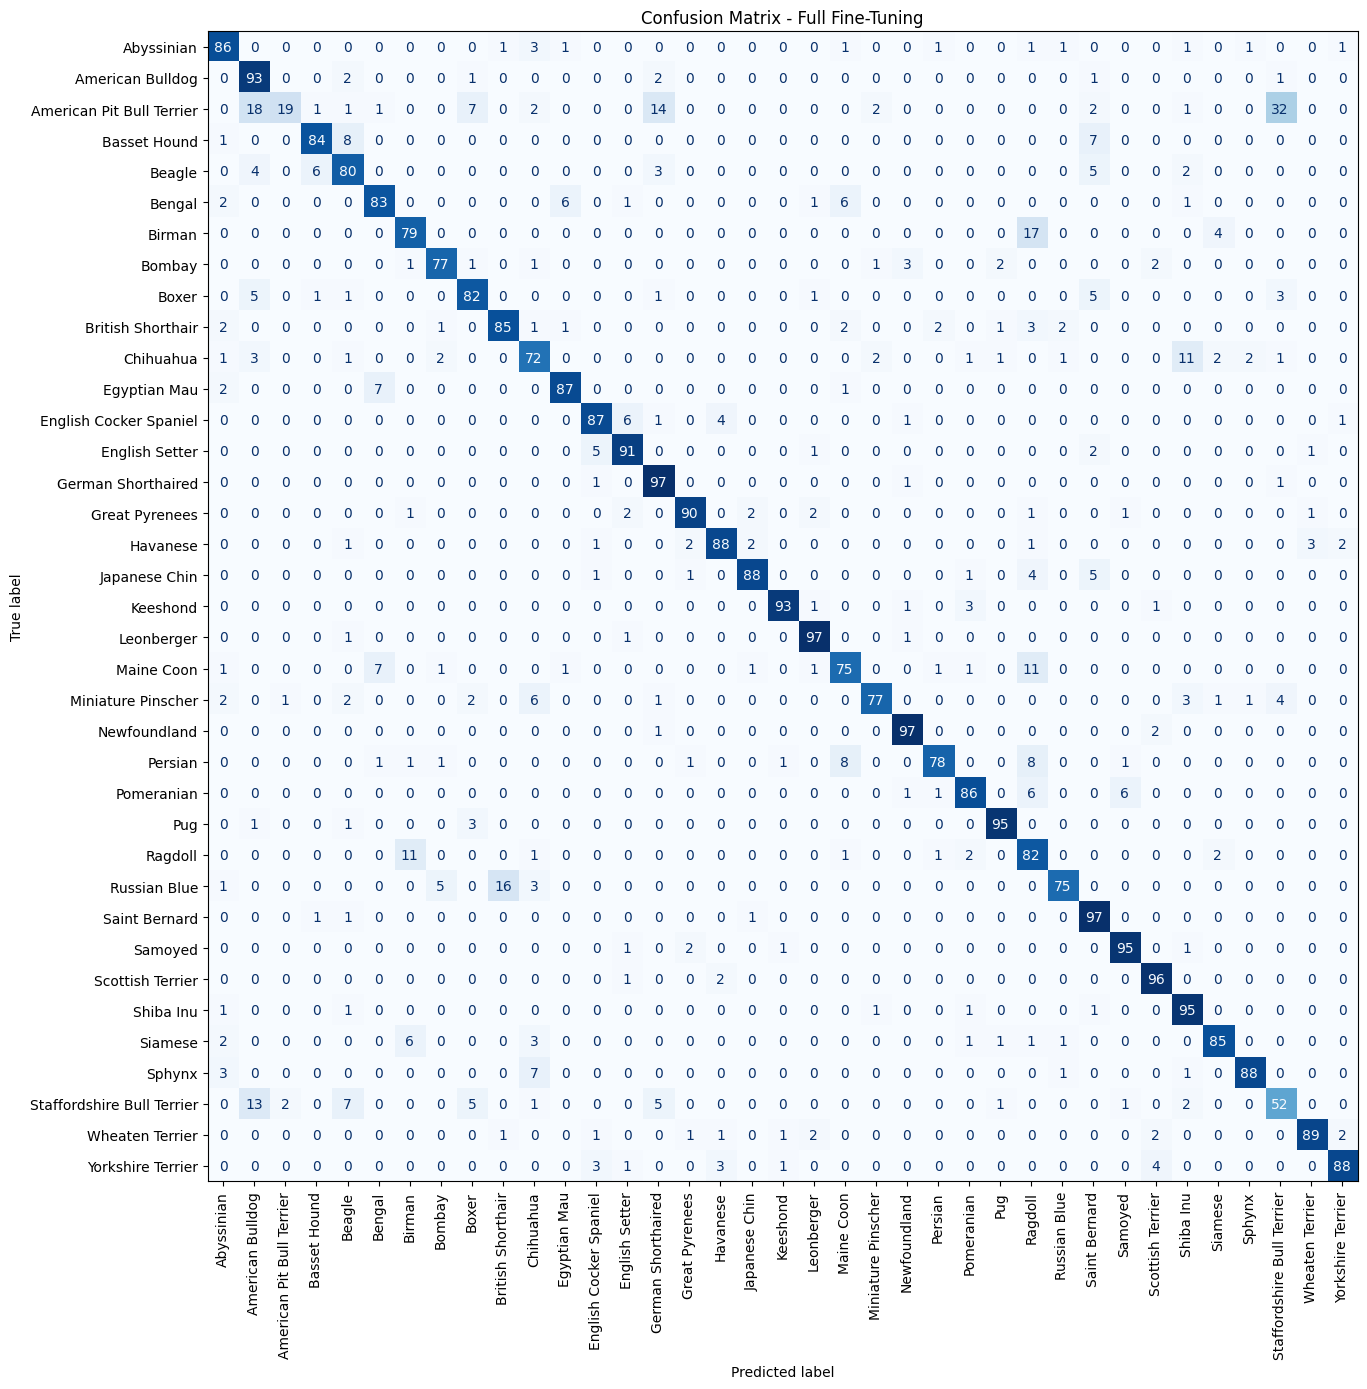

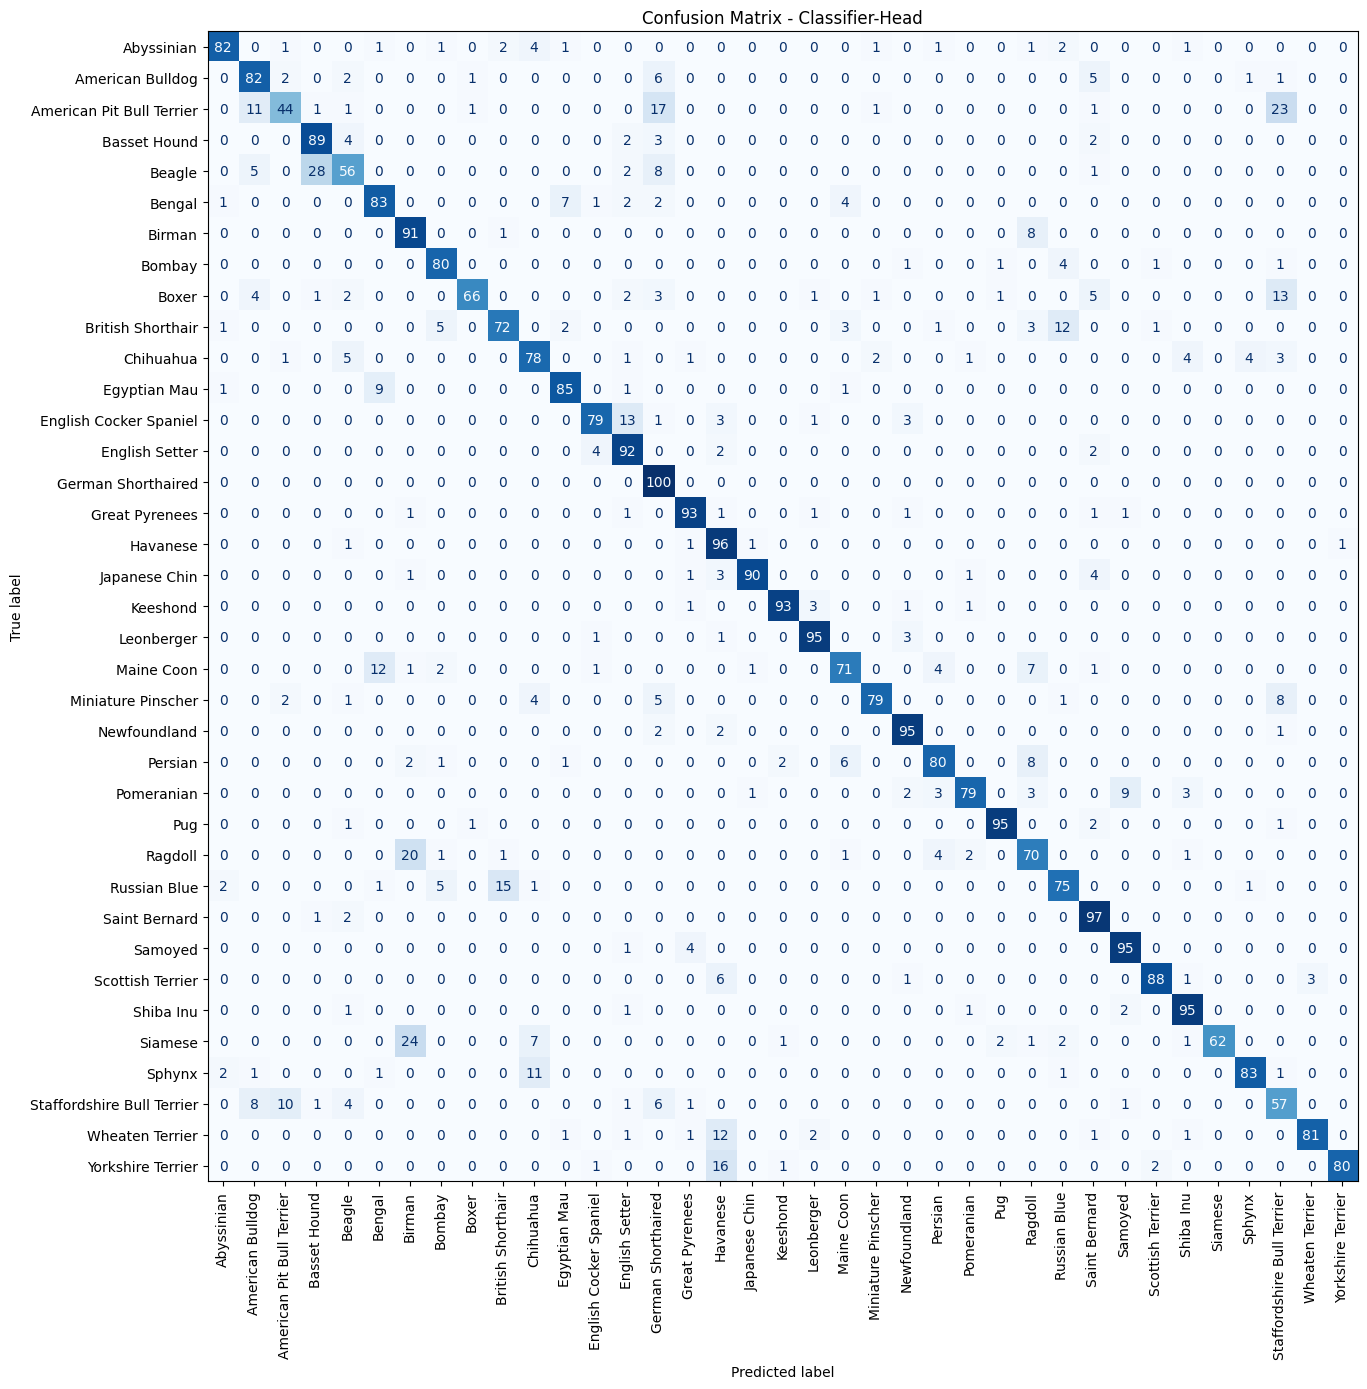

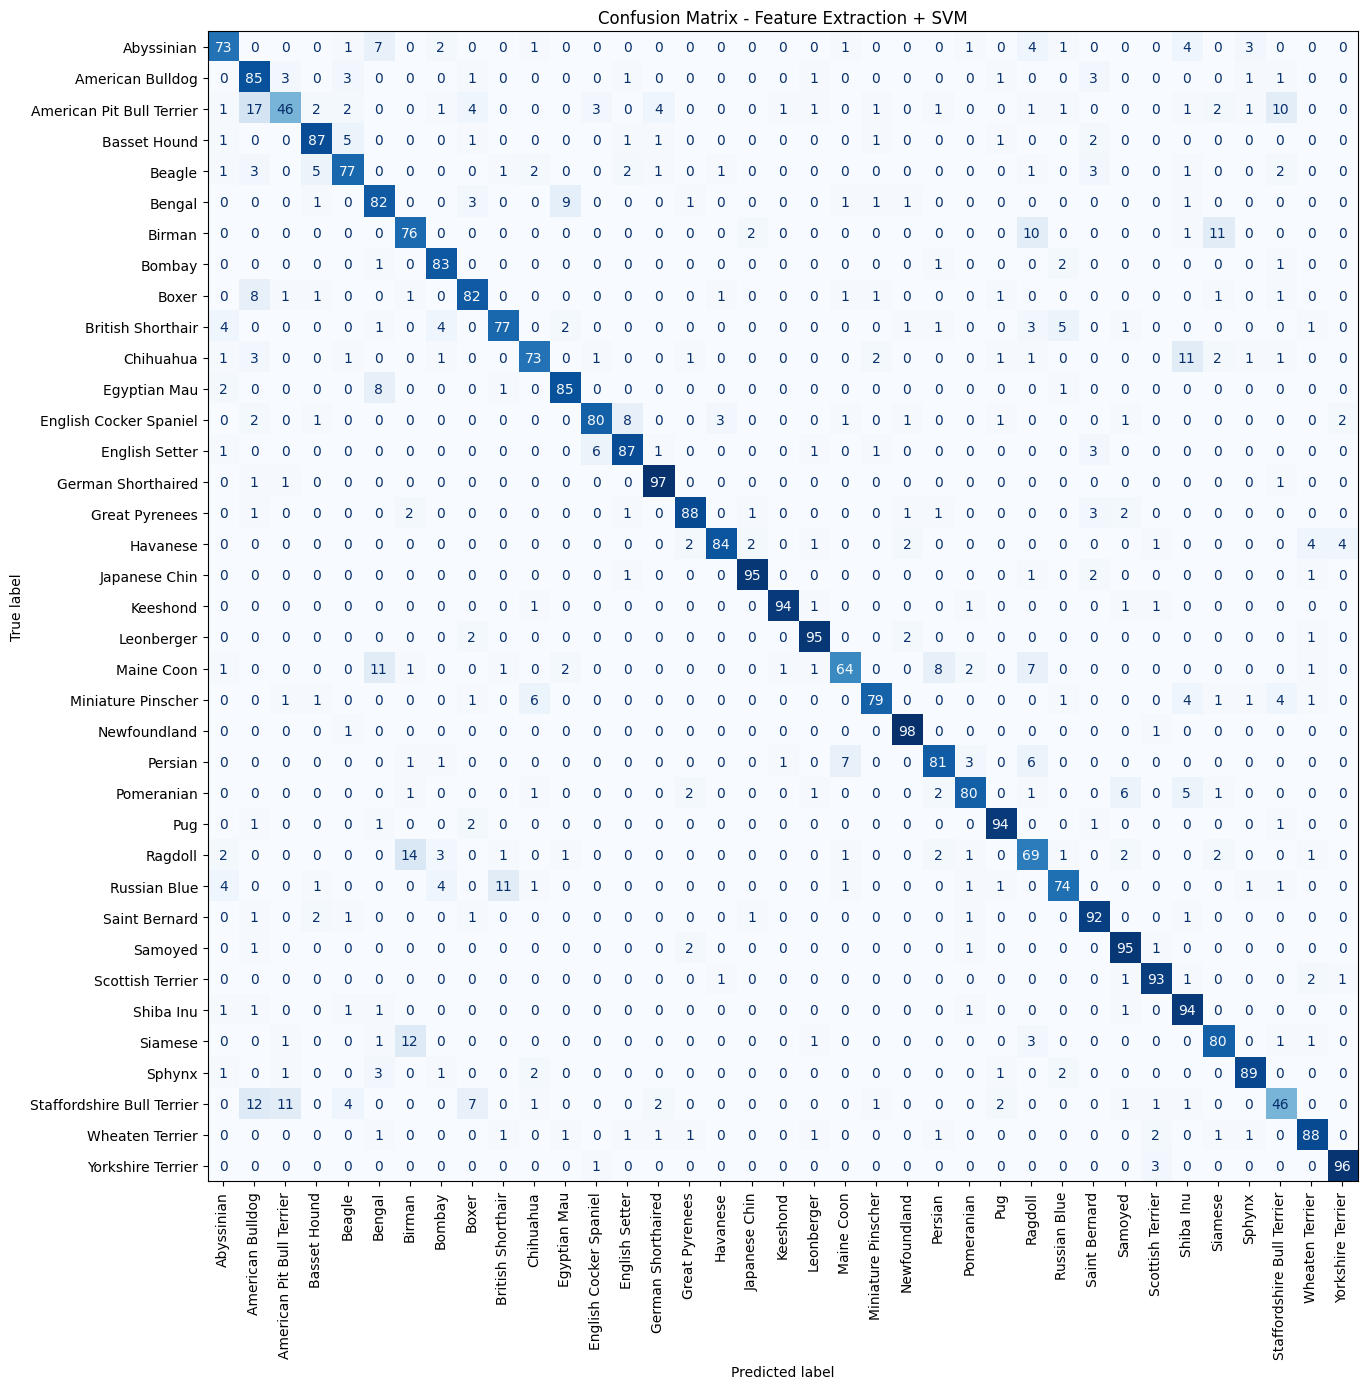

In [39]:
#Confusion Matrices :We'll generate three confusion
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Define model predictions
predictions = {
    "Full Fine-Tuning": y_pred_full,
    "Classifier-Head": y_pred_head,
    "Feature Extraction + SVM": y_pred_svm
}

# Get class names
class_names = train_data.classes

# Generate a confusion matrix for each approach
for name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(len(class_names))
    )

    fig, ax = plt.subplots(figsize=(16, 14))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(
        ax=ax,
        xticks_rotation=90,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

In [40]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Define predictions for all three approaches
predictions = {
    "Full Fine-Tuning": y_pred_full,
    "Classifier-Head": y_pred_head,
    "Feature Extraction + SVM": y_pred_svm
}

# Get the class names
class_names = train_data.classes

# Find the most confused class pairs
for model_name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(len(class_names))
    )

    # Remove correct predictions from the diagonal
    error_matrix = cm.copy()
    np.fill_diagonal(error_matrix, 0)

    # Sort errors from highest to lowest
    confused_pairs = np.dstack(
        np.unravel_index(
            np.argsort(error_matrix.ravel())[::-1],
            error_matrix.shape
        )
    )[0]

    print(f"\n{'='*55}")
    print(model_name)
    print("Top 10 most confused breed pairs:")
    print("="*55)

    count = 0

    for true_idx, pred_idx in confused_pairs:

        if error_matrix[true_idx, pred_idx] == 0:
            break

        print(
            f"{class_names[true_idx]} -> "
            f"{class_names[pred_idx]}: "
            f"{error_matrix[true_idx, pred_idx]} images"
        )

        count += 1

        if count == 10:
            break


Full Fine-Tuning
Top 10 most confused breed pairs:
American Pit Bull Terrier -> Staffordshire Bull Terrier: 32 images
American Pit Bull Terrier -> American Bulldog: 18 images
Birman -> Ragdoll: 17 images
Russian Blue -> British Shorthair: 16 images
American Pit Bull Terrier -> German Shorthaired: 14 images
Staffordshire Bull Terrier -> American Bulldog: 13 images
Ragdoll -> Birman: 11 images
Maine Coon -> Ragdoll: 11 images
Chihuahua -> Shiba Inu: 11 images
Persian -> Ragdoll: 8 images

Classifier-Head
Top 10 most confused breed pairs:
Beagle -> Basset Hound: 28 images
Siamese -> Birman: 24 images
American Pit Bull Terrier -> Staffordshire Bull Terrier: 23 images
Ragdoll -> Birman: 20 images
American Pit Bull Terrier -> German Shorthaired: 17 images
Yorkshire Terrier -> Havanese: 16 images
Russian Blue -> British Shorthair: 15 images
Boxer -> Staffordshire Bull Terrier: 13 images
English Cocker Spaniel -> English Setter: 13 images
British Shorthair -> Russian Blue: 12 images

Feature 

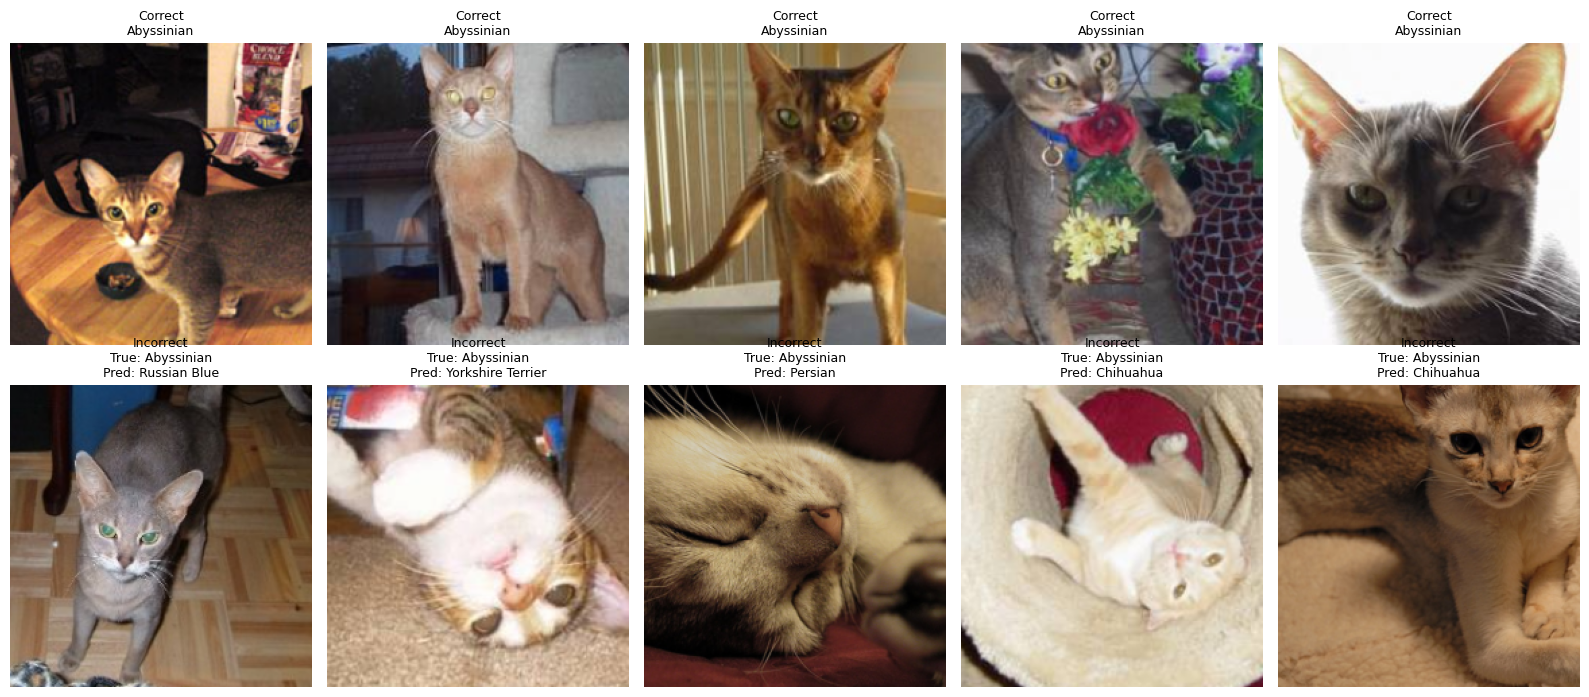

In [41]:
#Correct and Incorrect Predictions
import matplotlib.pyplot as plt
import numpy as np

# Find correct and incorrect predictions
correct_indices = np.where(y_test == y_pred_full)[0]
incorrect_indices = np.where(y_test != y_pred_full)[0]

# Select five examples of each type
selected_correct = correct_indices[:5]
selected_incorrect = incorrect_indices[:5]

# Combine selected indices
selected_indices = np.concatenate([
    selected_correct,
    selected_incorrect
])

# Display the selected test images
fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for i, idx in enumerate(selected_indices):

    # Retrieve the image and its true label
    image, true_label = test_dataset[idx]

    # Convert image to NumPy and unnormalize it
    image = image.permute(1, 2, 0).numpy()
    mean = np.array(weights.transforms().mean)
    std = np.array(weights.transforms().std)
    image = image * std + mean
    image = np.clip(image, 0, 1)

    # Get the predicted label
    predicted_label = y_pred_full[idx]

    # Display the image
    row = i // 5
    col = i % 5

    axes[row, col].imshow(image)
    axes[row, col].axis("off")

    if true_label == predicted_label:
        title = f"Correct\n{class_names[true_label]}"
    else:
        title = (
            f"Incorrect\nTrue: {class_names[true_label]}\n"
            f"Pred: {class_names[predicted_label]}"
        )

    axes[row, col].set_title(title, fontsize=9)

plt.tight_layout()
plt.show()

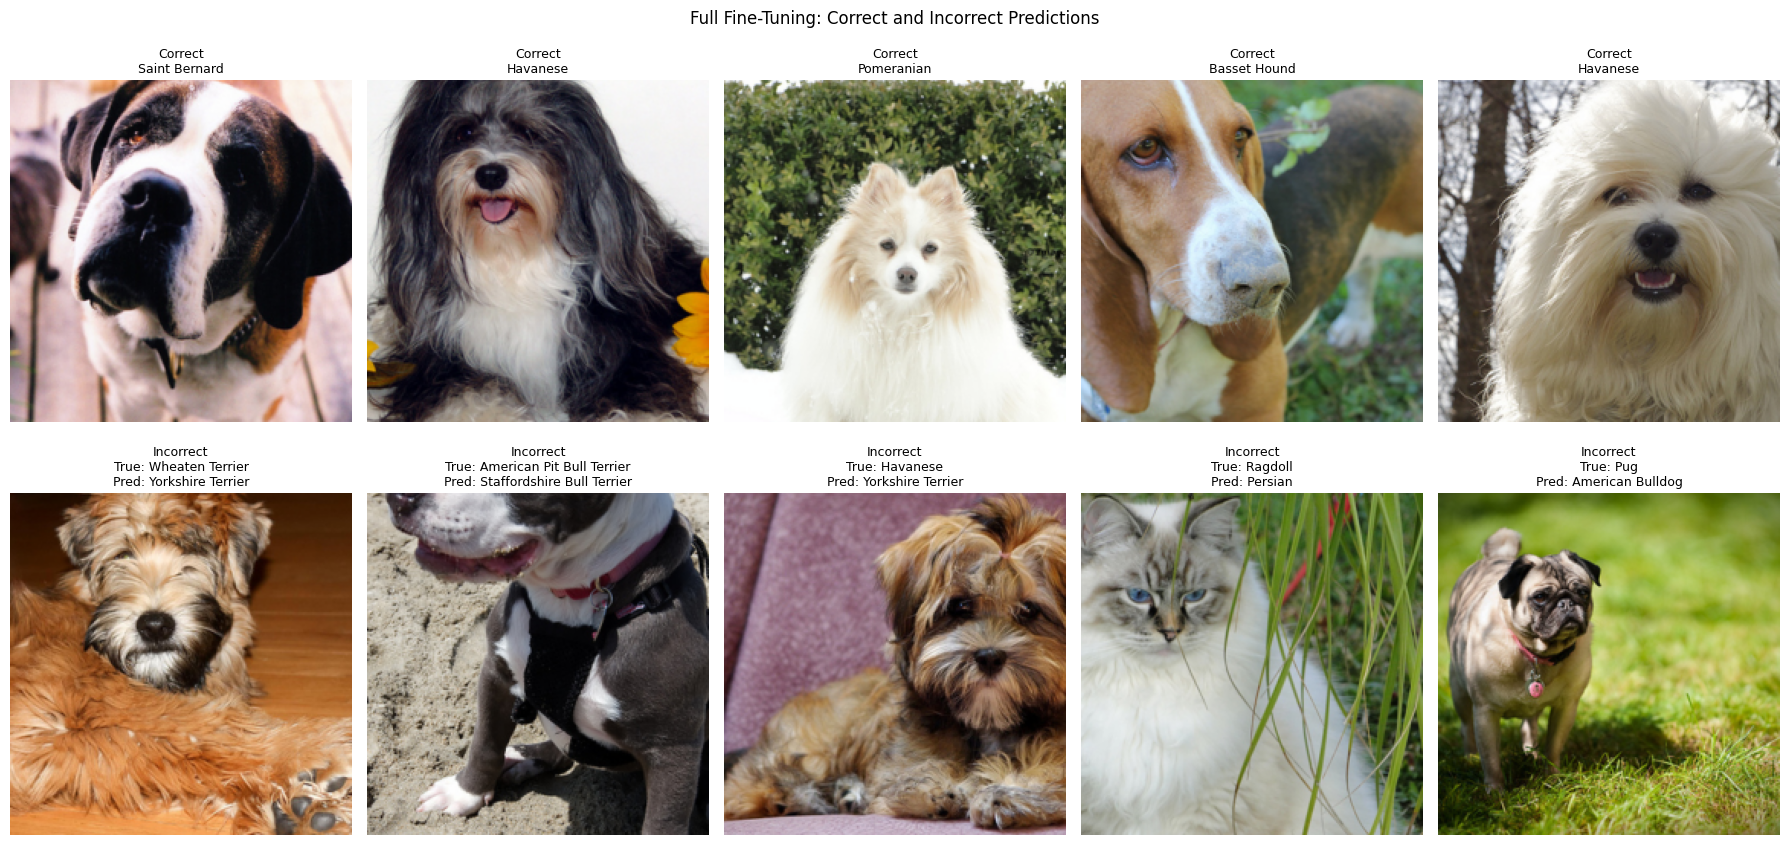

In [43]:
import matplotlib.pyplot as plt
import numpy as np

# Find correct and incorrect predictions
correct_indices = np.where(y_test == y_pred_full)[0]
incorrect_indices = np.where(y_test != y_pred_full)[0]

# Create a random generator for reproducibility
rng = np.random.default_rng(42)

# Randomly select five examples of each type
selected_correct = rng.choice(correct_indices, 5, replace=False)
selected_incorrect = rng.choice(incorrect_indices, 5, replace=False)

# Combine selected indices
selected_indices = np.concatenate([
    selected_correct,
    selected_incorrect
])

# Display selected test images
fig, axes = plt.subplots(2, 5, figsize=(18, 9))

for i, idx in enumerate(selected_indices):

    # Retrieve image and true label
    image, true_label = test_dataset[idx]

    # Convert image to NumPy and unnormalize it
    image = image.permute(1, 2, 0).numpy()
    mean = np.array(weights.transforms().mean)
    std = np.array(weights.transforms().std)
    image = image * std + mean
    image = np.clip(image, 0, 1)

    # Get predicted label
    predicted_label = y_pred_full[idx]

    # Determine subplot position
    row = i // 5
    col = i % 5

    axes[row, col].imshow(image)
    axes[row, col].axis("off")

    if true_label == predicted_label:
        title = f"Correct\n{class_names[true_label]}"
    else:
        title = (
            f"Incorrect\nTrue: {class_names[true_label]}\n"
            f"Pred: {class_names[predicted_label]}"
        )

    axes[row, col].set_title(title, fontsize=9)

fig.suptitle("Full Fine-Tuning: Correct and Incorrect Predictions")
plt.tight_layout()
plt.show()

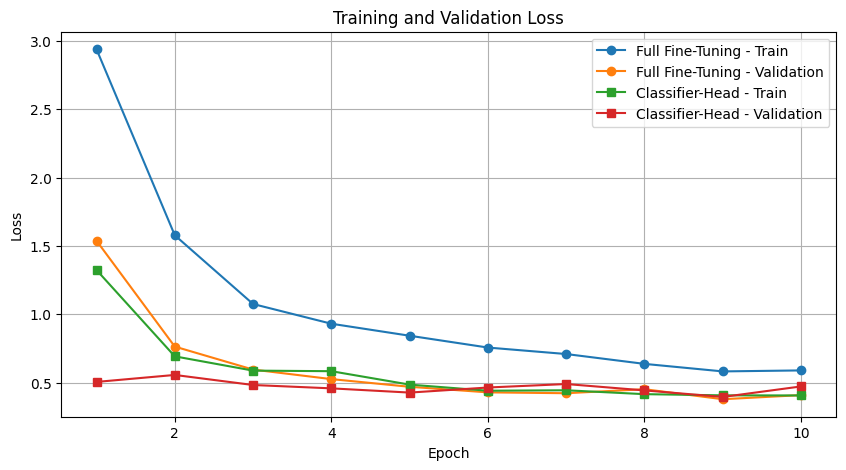

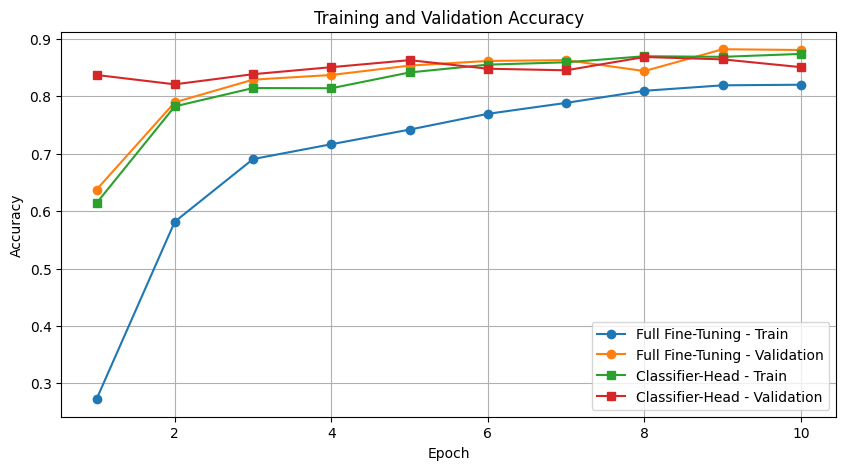

In [44]:
#Step 9 – Training Curves
import matplotlib.pyplot as plt

# Define epoch numbers
epochs = range(1, 11)

# Plot training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(epochs, history["train_loss"], marker="o", label="Full Fine-Tuning - Train")
plt.plot(epochs, history["val_loss"], marker="o", label="Full Fine-Tuning - Validation")

plt.plot(epochs, history_head["train_loss"], marker="s", label="Classifier-Head - Train")
plt.plot(epochs, history_head["val_loss"], marker="s", label="Classifier-Head - Validation")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


# Plot training and validation accuracy
plt.figure(figsize=(10, 5))

plt.plot(epochs, history["train_accuracy"], marker="o", label="Full Fine-Tuning - Train")
plt.plot(epochs, history["val_accuracy"], marker="o", label="Full Fine-Tuning - Validation")

plt.plot(epochs, history_head["train_accuracy"], marker="s", label="Classifier-Head - Train")
plt.plot(epochs, history_head["val_accuracy"], marker="s", label="Classifier-Head - Validation")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [45]:
#Step 10 – Final Comparison
import pandas as pd

# Create the final comparison table
comparison_data = {
    "Approach": [
        "Full Fine-Tuning",
        "Classifier-Head",
        "Feature Extraction + SVM"
    ],

    "Validation Accuracy (%)": [
        87.77,
        88.18,
        87.50
    ],

    "Test Accuracy (%)": [
        results["Full Fine-Tuning"]["accuracy"] * 100,
        results["Classifier-Head"]["accuracy"] * 100,
        results["Feature Extraction + SVM"]["accuracy"] * 100
    ],

    "Macro F1-score": [
        results["Full Fine-Tuning"]["macro_f1"],
        results["Classifier-Head"]["macro_f1"],
        results["Feature Extraction + SVM"]["macro_f1"]
    ],

    "Trainable Parameters": [
        1555781,
        628773,
        0
    ],

    "Training Time (min)": [
        training_time / 60,
        training_time_head / 60,
        (extraction_time + svm_training_time) / 60
    ]
}

comparison_df = pd.DataFrame(comparison_data)

# Display the comparison table
display(comparison_df.round(3))

,Approach,Validation Accuracy (%),Test Accuracy (%),Macro F1-score,Trainable Parameters,Training Time (min)
0,Full Fine-Tuning,87.77,84.710,0.842,1555781,3.704
1,Classifier-Head,88.18,82.529,0.824,628773,3.282
2,Feature Extraction + SVM,87.50,83.347,0.831,0,37.706


In [46]:
#Step 11 – Organize the project
import os

# Display the current project files
for root, dirs, files in os.walk("."):

    # Ignore unnecessary folders
    dirs[:] = [
        d for d in dirs
        if d not in ["__pycache__", ".config"]
    ]

    level = root.count(os.sep)

    if level > 2:
        continue

    print(f"\nFolder: {root}")

    for file in files:
        print(f"  - {file}")


Folder: .
  - best_full_finetuning.pth
  - best_classifier_head.pth

Folder: ./data

Folder: ./data/oxford-iiit-pet
  - annotations.tar.gz
  - images.tar.gz

Folder: ./sample_data
  - README.md
  - anscombe.json
  - california_housing_test.csv
  - mnist_train_small.csv
  - mnist_test.csv
  - california_housing_train.csv


In [47]:
#Step 12 – Save the SVM model and Scaler
import joblib

# Save the best SVM classifier
joblib.dump(best_svm, "best_svm_model.joblib")

# Save the fitted StandardScaler
joblib.dump(scaler, "standard_scaler.joblib")

print("SVM model saved successfully!")
print("StandardScaler saved successfully!")

SVM model saved successfully!
StandardScaler saved successfully!


In [48]:
# Step 13 –Verify files and environment
import sys
import torch
import torchvision
import sklearn
import numpy
import pandas
import joblib

# Display environment information
print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("TorchVision version:", torchvision.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("NumPy version:", numpy.__version__)
print("Pandas version:", pandas.__version__)
print("Joblib version:", joblib.__version__)

# List saved model files
print("\nSaved files:")

for file in os.listdir("."):
    if file.endswith((".pth", ".joblib")):
        print(file)

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch version: 2.14.1+cu130
TorchVision version: 0.29.1+cu130
Scikit-learn version: 1.6.1
NumPy version: 2.4.6
Pandas version: 2.2.3
Joblib version: 1.6.0

Saved files:
best_full_finetuning.pth
standard_scaler.joblib
best_svm_model.joblib
best_classifier_head.pth


In [49]:
# Create the requirements.txt file
requirements = """torch==2.14.1
torchvision==0.29.1
scikit-learn==1.6.1
numpy==2.4.6
pandas==2.2.3
joblib==1.6.0
matplotlib
pillow
"""

with open("requirements.txt", "w") as file:
    file.write(requirements)

print("requirements.txt created successfully!")

print("\nFile content:")
print(requirements)

requirements.txt created successfully!

File content:
torch==2.14.1
torchvision==0.29.1
scikit-learn==1.6.1
numpy==2.4.6
pandas==2.2.3
joblib==1.6.0
matplotlib
pillow

